# L2B validation: Chl-a and SPM against the GIPREB monitoring network

This notebook compares the water-quality parameters retrieved from Sentinel-2 by GRS (L2B
products) with the in situ measurements of the [GIPREB](https://www.etangdeberre.org) monitoring
network in the Berre lagoon (France), where the HYPERNETS station `BEFR` is also installed.

**Workflow**

1. load the in situ database (monthly samples at the surface and at the bottom of 10 stations);
2. build the multi-temporal L2B datacube over a box centred on one station ({class}`grstbx.L2grs`);
3. clean the satellite pixels (GRS mask, optical water type) and compute, for each image, the median
   and the inter-quartile range within the box; discard the images with too few valid pixels or a
   too heterogeneous box;
4. compare the satellite and in situ time series;
5. compute the agreement statistics of the matchups (satellite image within a given lag of the in
   situ sample).

**Data**

| data | source |
|---|---|
| in situ | GIPREB database 1994-2023: Niskin bottle sampling, Chl-a by fluorimetry, suspended particulate matter (SPM, *MES*) by filtration and weighing |
| satellite | GRS L2B products (v2.2.1) of Sentinel-2 A/B subsets around the BEFR station |

The input data are not distributed with grstbx: set the paths of the configuration cell to your
own files to run the notebook.

## Setup

Imports, then the configuration: GIPREB station and sampling depth, paths of the satellite data, study
period and size of the box, quality-control thresholds, and the parameters compared (`PARAMS`: L2B
variable, in situ variable and axis label).

In [1]:
import glob
import os
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import rioxarray  # activate the rio accessor
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

import grstbx

opj = os.path.join

plt.rcParams.update({'font.family': 'serif', 'mathtext.fontset': 'stix',
                     'font.size': 13, 'axes.labelsize': 14,
                     'figure.dpi': 80})

print(f'grstbx: {grstbx.__version__}')

grstbx: 2.1.1


In [2]:
# ---- in situ data
INSITU_FILE = '/DATA/data/gipreb/BDD_HYDRO_GIPREB_compil_1994-2023.csv'
STATION = 'H12'          # GIPREB station used for the comparison
DEPTH = 'S'              # sampling depth: 'S' surface, 'F' bottom

# ---- satellite data
SITE = 'BEFR'
L2B_DIR = '/data/satellite/Sentinel-2/subset/hypernets/L2B_v221'
DATACUBE_DIR = '/data/satellite/Sentinel-2/subset/datacube'   # cache of the datacubes
START_DATE, END_DATE = '2017-01-01', '2024-12-31'
BOX_SIZE = 400           # side of the square box centred on the station (m);
                         # delete the cached datacube when changing it

# ---- quality control of the satellite pixels / images
OWT_DIST_MIN = -0.12     # minimum distance to the optical water types of Spyrakos et al. (2018)
MIN_VALID_FRACTION = 0.5 # minimum proportion of valid pixels within the box
MAX_CV = 0.3             # maximum coefficient of variation (std / median) within the box

# ---- comparison: satellite parameter -> (in situ variable, label of the axes)
PARAMS = {'Chla_OC2nasa': ('Chla_ug/l', r'$Chl$-$a\ (\mu g\ L^{-1})$'),
          'SPM_nechad': ('MES_mg/l', r'$SPM\ (mg\ L^{-1})$')}
MAX_LAG = pd.Timedelta('1D')   # maximum time lag between satellite and in situ data

## 1. In situ data

The GIPREB file holds one row per date, station and depth. It is converted into an
{class}`xarray.Dataset` with the `date`, `nom_station` and `Profondeur_m` dimensions; the position of
each station is the average of the positions recorded at each sampling.

In [3]:
df = pd.read_csv(INSITU_FILE, skiprows=9, na_values=999999)
df['date'] = pd.to_datetime(df.date, format='%Y-%m-%d')
df = df.set_index(['date', 'nom_station', 'Profondeur_m'])
df = df[~df.index.duplicated(keep='first')]
insitu = df.to_xarray()
insitu['clat'] = insitu.Latitude_WGS84_degres.isel(Profondeur_m=0).mean('date')
insitu['clon'] = insitu.Longitude_WGS84_degres.isel(Profondeur_m=0).mean('date')

clon, clat = float(insitu.clon.sel(nom_station=STATION)), float(insitu.clat.sel(nom_station=STATION))
print(f'station {STATION}: lon={clon:.4f}, lat={clat:.4f}')
insitu

station H12: lon=5.0972, lat=43.4423


<xarray.Dataset> Size: 652kB
Dimensions:                 (date: 312, nom_station: 10, Profondeur_m: 2)
Coordinates:
  * date                    (date) datetime64[ns] 2kB 1994-06-29 ... 2023-12-11
  * nom_station             (nom_station) object 80B 'H01' 'H03' ... 'H18' 'H19'
  * Profondeur_m            (Profondeur_m) object 16B 'F' 'S'
Data variables: (12/15)
    Latitude_WGS84_degres   (date, nom_station, Profondeur_m) float64 50kB 43...
    Longitude_WGS84_degres  (date, nom_station, Profondeur_m) float64 50kB 5....
    NO3_umol/l              (date, nom_station, Profondeur_m) float64 50kB 1....
    NO2_umol/l              (date, nom_station, Profondeur_m) float64 50kB 0....
    NH4_umol/l              (date, nom_station, Profondeur_m) float64 50kB 3....
    PO4_umol/l              (date, nom_station, Profondeur_m) float64 50kB 0....
    ...                      ...
    Ptot_umol/l             (date, nom_station, Profondeur_m) float64 50kB 1....
    MES_mg/l                (date, nom_station, Profondeur_m) float64 50kB 19...
    Chla_ug/l               (date, nom_station, Profondeur_m) float64 50kB 7....
    Phaeo_g/l               (date, nom_station, Profondeur_m) float64 50kB 1....
    clat                    (nom_station) float64 80B 43.53 43.48 ... 43.47
    clon                    (nom_station) float64 80B 5.024 5.018 ... 5.207

Time series of Chl-a, phaeopigments and SPM (*MES*) at the surface (`S`) and at the bottom (`F`) of the station:

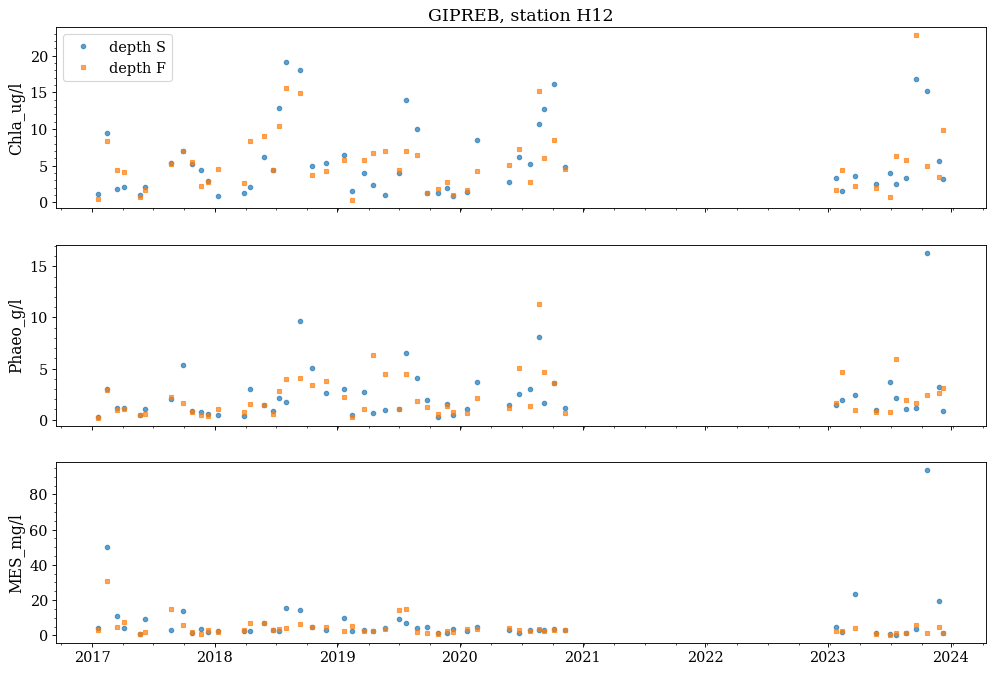

In [4]:
time_range = slice(START_DATE, END_DATE)
fig, axs = plt.subplots(nrows=3, figsize=(15, 10), sharex=True)
for ax, var in zip(axs, ['Chla_ug/l', 'Phaeo_g/l', 'MES_mg/l']):
    for depth, marker in zip(['S', 'F'], ['o', 's']):
        data = insitu[var].sel(date=time_range, nom_station=STATION, Profondeur_m=depth)
        ax.plot(data.date.values, data.values, marker=marker, ms=4, ls='', alpha=0.7, label=f'depth {depth}')
    ax.set_ylabel(var)
    ax.minorticks_on()
axs[0].legend()
axs[0].set_title(f'GIPREB, station {STATION}');

## 2. Satellite datacube

The L2B products are stored as `L2B_DIR/SITE/YYYY/MM/DD/<product>.nc`. The datacube is cropped to a
square box centred on the station ({meth}`grstbx.SpatioTemp.wktbox`) and cached as a netCDF file,
since loading several hundreds of images takes a while.

In [5]:
def list_grs_products(rootdir, site, pattern='*'):
    """
    List the GRS products stored as ``rootdir/site/YYYY/MM/DD/<product>``.

    The product names follow the ESA convention
    ``<satellite>_<level>_<time>_<baseline>_<orbit>_<tile>_<processing time>``.

    :return: pandas.DataFrame indexed (and sorted) by acquisition time, with the path of each product
    """
    paths = sorted(glob.glob(opj(rootdir, site, '*', '*', '*', pattern)))
    if not paths:
        raise FileNotFoundError(f'no product found in {opj(rootdir, site)}')
    names = pd.Series([os.path.basename(p) for p in paths])
    products = names.str.split('_', expand=True).iloc[:, :7]
    products.columns = ['satellite', 'level', 'time', 'baseline', 'orbit', 'tile', 'processing_time']
    products['time'] = pd.to_datetime(products['time'])
    products['path'] = paths
    return products.set_index('time').sort_index()

In [6]:
products = list_grs_products(L2B_DIR, SITE)
files = products[START_DATE:END_DATE].path.values
print(f'{len(files)} L2B products from {START_DATE} to {END_DATE}')
products.head()

732 L2B products from 2017-01-01 to 2024-12-31


,satellite,level,baseline,orbit,tile,processing_time,path
time,,,,,,,
2017-01-03 10:44:32,S2A,MSIL2B,N0500,R008,T31TFJ,20230926T025711.nc,/data/satellite/Sentinel-2/subset/hypernets/L2...
2017-01-13 10:44:01,S2A,MSIL2B,N0500,R008,T31TFJ,20231025T155034.nc,/data/satellite/Sentinel-2/subset/hypernets/L2...
2017-02-02 10:42:41,S2A,MSIL2B,N0500,R008,T31TFJ,20231025T004856.nc,/data/satellite/Sentinel-2/subset/hypernets/L2...
2017-02-19 10:30:51,S2A,MSIL2B,N0500,R108,T31TFJ,20231025T084923.nc,/data/satellite/Sentinel-2/subset/hypernets/L2...
2017-02-22 10:40:31,S2A,MSIL2B,N0500,R008,T31TFJ,20231026T035832.nc,/data/satellite/Sentinel-2/subset/hypernets/L2...


In [7]:
box = grstbx.SpatioTemp().wktbox(clon, clat, width=BOX_SIZE, height=BOX_SIZE)
bbox = gpd.GeoDataFrame(geometry=gpd.GeoSeries.from_wkt([box]), crs=4326)

os.makedirs(DATACUBE_DIR, exist_ok=True)
dc_path = opj(DATACUBE_DIR, f'{SITE}_{START_DATE}_{END_DATE}_{STATION}.nc')
if not os.path.exists(dc_path):
    dc = grstbx.L2grs(files)
    dc.get_l2b_datacube(subset=bbox)
    dc.datacube.to_netcdf(dc_path)

dcube = xr.open_dataset(dc_path, decode_coords='all').drop_duplicates('time').load()
dcube

<xarray.Dataset> Size: 31MB
Dimensions:                 (time: 717, y: 21, x: 21)
Coordinates:
  * time                    (time) datetime64[ns] 6kB 2017-01-03T10:44:32 ......
  * x                       (x) float64 168B 6.695e+05 6.695e+05 ... 6.699e+05
    band                    int64 8B 1
    spatial_ref             int64 8B 0
  * y                       (y) float64 168B 4.812e+06 4.812e+06 ... 4.812e+06
Data variables: (12/14)
    owt_dist_Spyrakos2018   (time, y, x) float64 3MB -0.04454 ... -0.04796
    owt_index_Spyrakos2018  (time, y, x) float64 3MB 9.0 9.0 9.0 ... 9.0 9.0 9.0
    owt_dist_Bi2024         (time, y, x) float64 3MB -0.04694 ... -0.04878
    owt_index_Bi2024        (time, y, x) float64 3MB 6.0 6.0 6.0 ... 6.0 6.0 6.0
    Chla_OC2nasa            (time, y, x) float64 3MB 2.649 2.339 ... 3.746 4.458
    Chla_M09B               (time, y, x) float64 3MB 3.351 nan ... 25.21 7.453
    ...                      ...
    SPM_nechad              (time, y, x) float64 3MB 4.367 3.939 ... 3.368 2.997
    acdom_B15               (time, y, x) float64 3MB 1.602 1.584 ... 2.307 2.03
    Kd_par                  (time, y, x) float64 3MB 1.978 1.898 ... 2.455 2.474
    flags                   (time, y, x) int64 3MB 536 536 536 ... 536 536 536
    mask                    (time, y, x) uint8 316kB 0 0 0 0 0 0 ... 0 0 0 0 0 0
    valid_pix_prop          (time) float64 6kB 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
Attributes: (12/74)
    long_name:                           CA BLUE GREEN RED VRE_1 VRE_2 VRE_3 ...
    constellation:                       Sentinel-2
    constellation_id:                    S2
    product_path:                        /data/satellite/Sentinel-2/L1C/31TFJ...
    product_name:                        S2A_MSIL1C_20170103T104432_N0500_R00...
    product_filename:                    S2A_MSIL1C_20170103T104432_N0500_R00...
    ...                                  ...
    dirdata:                             /data/grs/grsdata
    abs_gas_file:                        /home/harmel/Dropbox/Dropbox/work/gi...
    water_vapor_transmittance_file:      /home/harmel/Dropbox/Dropbox/work/gi...
    metadata_profile:                    datacube
    start_date:                          2017-01-03T10:44:32.000000000
    stop_date:                           2024-12-29T10:34:41.000000000

Chl-a (OC2) images of the datacube over one month (September 2023):

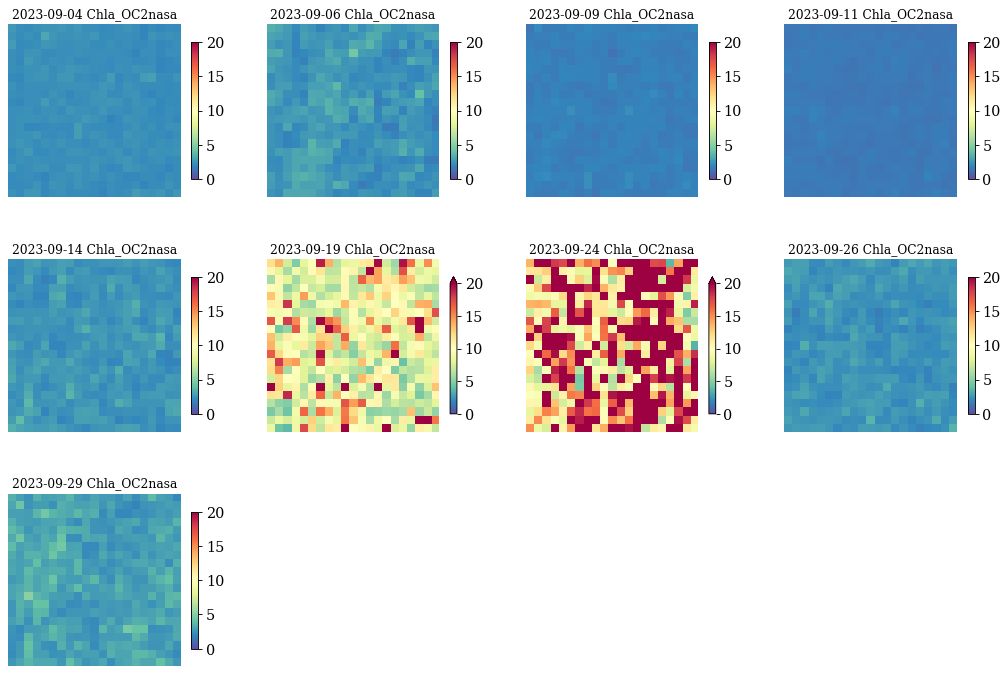

In [8]:
param = 'Chla_OC2nasa'
month = dcube.sel(time=slice('2023-09-01', '2023-09-30'))
proj = ccrs.epsg(dcube.rio.crs.to_epsg())

ncols = min(4, month.sizes['time'])
nrows = int(np.ceil(month.sizes['time'] / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3.6), squeeze=False,
                        subplot_kw={'projection': proj})
for ax in axs.flat:
    ax.set_axis_off()
for ax, (time, raster) in zip(axs.flat, month.groupby('time')):
    raster = raster.squeeze('time')
    raster[param].where(raster.mask == 0).plot.imshow(ax=ax, vmin=0, vmax=20, cmap=plt.cm.Spectral_r,
                                                      cbar_kwargs={'shrink': 0.7, 'label': ''})
    ax.set_title(pd.Timestamp(time).strftime('%Y-%m-%d') + ' ' + param, fontsize=11)

## 3. Quality control of the satellite data

The pixels are kept when

- the GRS `mask` is 0 (valid water pixel),
- the reflectance spectrum is close enough to one of the optical water types of Spyrakos et al.
  (2018): `owt_dist_Spyrakos2018 > OWT_DIST_MIN`; this discards the spectra contaminated by clouds,
  shadows, sunglint residuals or the bottom.

For each image, the statistics of the valid pixels within the box are computed. The image is kept
when at least `MIN_VALID_FRACTION` of the pixels are valid and when the box is homogeneous enough
(coefficient of variation lower than `MAX_CV`).

In [9]:
def box_statistics(dcube, param):
    """Per-image statistics of the valid pixels of ``param`` within the box."""
    valid = dcube[param].where(dcube.mask == 0).where(dcube.owt_dist_Spyrakos2018 > OWT_DIST_MIN)
    with warnings.catch_warnings():  # images without any valid pixel
        warnings.simplefilter('ignore', RuntimeWarning)
        stats = xr.Dataset({'median': valid.median(['x', 'y']),
                            'q25': valid.quantile(0.25, ['x', 'y']).drop_vars('quantile'),
                            'q75': valid.quantile(0.75, ['x', 'y']).drop_vars('quantile'),
                            'std': valid.std(['x', 'y']),
                            'valid_fraction': valid.count(['x', 'y']) / (dcube.sizes['x'] * dcube.sizes['y'])})
    stats['cv'] = stats['std'] / stats['median']
    stats['good'] = (stats.valid_fraction >= MIN_VALID_FRACTION) & (stats.cv <= MAX_CV)
    return stats, valid


sat_stats, sat_valid = {}, {}
for param in PARAMS:
    sat_stats[param], sat_valid[param] = box_statistics(dcube, param)
    n_good = int(sat_stats[param].good.sum())
    print(f'{param}: {n_good} good images out of {dcube.sizes["time"]}')

Chla_OC2nasa: 532 good images out of 717
SPM_nechad: 533 good images out of 717


Proportion of valid pixels and coefficient of variation of each image for Chl-a; the dashed lines mark the thresholds `MIN_VALID_FRACTION` and `MAX_CV`:

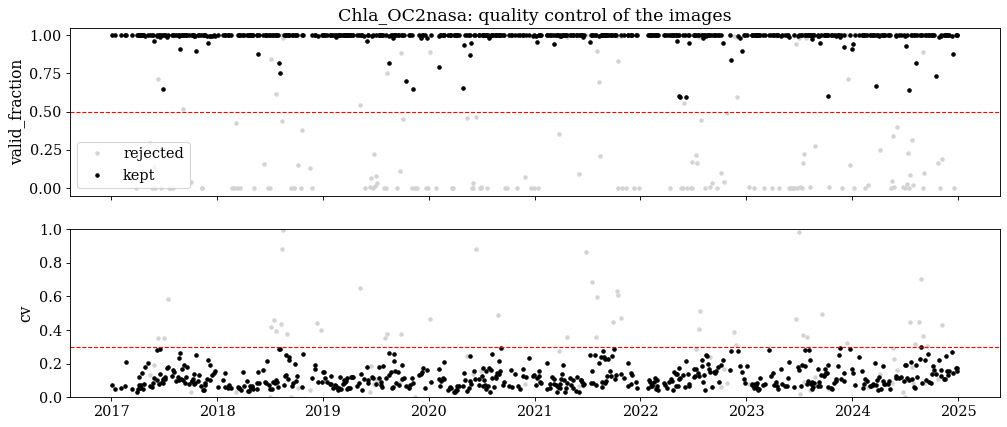

In [10]:
stats = sat_stats['Chla_OC2nasa']
fig, axs = plt.subplots(nrows=2, figsize=(15, 6), sharex=True)
for ax, var, thresh in zip(axs, ['valid_fraction', 'cv'], [MIN_VALID_FRACTION, MAX_CV]):
    ax.plot(stats.time.values, stats[var].values, 'o', ms=3, c='lightgrey', label='rejected')
    good = stats.where(stats.good, drop=True)
    ax.plot(good.time.values, good[var].values, 'o', ms=3, c='k', label='kept')
    ax.axhline(thresh, c='r', ls='--', lw=1)
    ax.set_ylabel(var)
axs[1].set_ylim(0, 1)
axs[0].legend(loc='lower left')
axs[0].set_title('Chla_OC2nasa: quality control of the images');

Distribution of the values of the valid pixels of the images kept by the quality control:

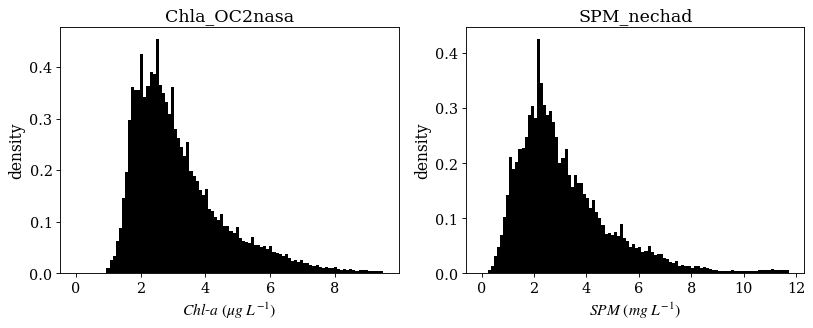

In [11]:
fig, axs = plt.subplots(ncols=len(PARAMS), figsize=(6 * len(PARAMS), 4))
for ax, (param, (insitu_var, label)) in zip(axs, PARAMS.items()):
    values = sat_valid[param].sel(time=sat_stats[param].good).values.ravel()
    values = values[np.isfinite(values)]
    ax.hist(values, bins=100, range=(0, np.nanquantile(values, 0.99)), density=True, color='k')
    ax.set_xlabel(label)
    ax.set_ylabel('density')
    ax.set_title(param);

## 4. Time series

Median (dots) and inter-quartile range (error bars) of the satellite retrievals within the box, for
the images that passed the quality control, together with the in situ measurements at the surface
and at the bottom of the station: Chl-a, then SPM.

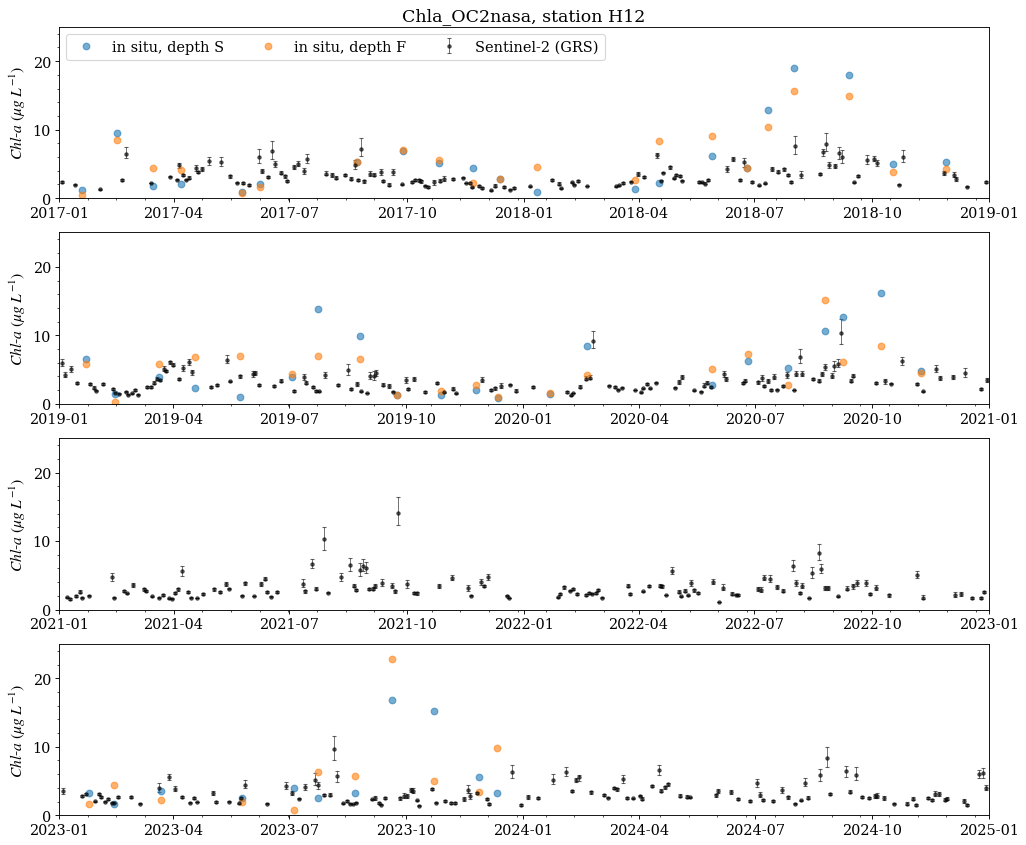

In [12]:
def plot_time_series(param, years_per_row=2):
    insitu_var, label = PARAMS[param]
    stats = sat_stats[param].where(sat_stats[param].good, drop=True)
    years = range(pd.Timestamp(START_DATE).year, pd.Timestamp(END_DATE).year + 1, years_per_row)
    insitu_max = float(insitu[insitu_var].sel(date=slice(START_DATE, END_DATE), nom_station=STATION).max())
    ymax = 1.1 * max(float(stats.q75.max()), insitu_max)

    fig, axs = plt.subplots(nrows=len(years), figsize=(15, 3.2 * len(years)), sharey=True)
    for ax, year in zip(np.atleast_1d(axs), years):
        ax.errorbar(stats.time.values, stats['median'].values,
                    yerr=[(stats['median'] - stats.q25).values, (stats.q75 - stats['median']).values],
                    fmt='o', ms=3, c='k', capsize=2, elinewidth=0.8, alpha=0.6, label='Sentinel-2 (GRS)')
        for depth, color in zip(['S', 'F'], ['tab:blue', 'tab:orange']):
            data = insitu[insitu_var].sel(nom_station=STATION, Profondeur_m=depth)
            ax.plot(data.date.values, data.values, 'o', ms=6, alpha=0.6, c=color, label=f'in situ, depth {depth}')
        ax.set_xlim(pd.Timestamp(f'{year}-01-01'), pd.Timestamp(f'{year + years_per_row}-01-01'))
        ax.set_ylim(0, ymax)
        ax.set_ylabel(label)
        ax.minorticks_on()
    np.atleast_1d(axs)[0].legend(loc='upper left', ncols=3)
    np.atleast_1d(axs)[0].set_title(f'{param}, station {STATION}')


plot_time_series('Chla_OC2nasa')

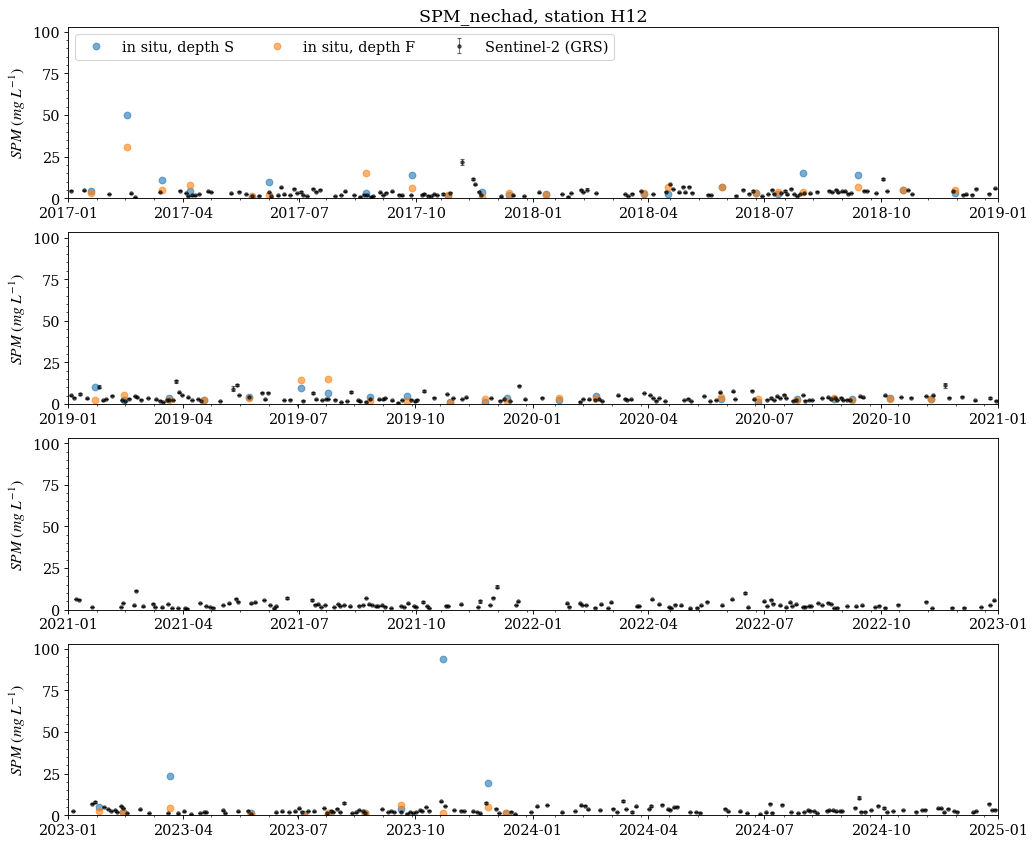

In [13]:
plot_time_series('SPM_nechad')

`TURB_dogliotti` (turbidity, FNU) can be compared to the in situ SPM in the same way by adding it to
`PARAMS`.

## 5. Matchups

Each in situ sample at depth `DEPTH` is paired with the closest satellite image (passing the quality
control) acquired within `MAX_LAG` ({func}`~grstbx.matchup.get_matchups`). The agreement statistics
({func}`~grstbx.matchup.matchup_metrics`) are displayed on the scatter plots ({func}`~grstbx.matchup.plot_matchup`):

- slope, intercept and Pearson's r of the linear regression of the satellite vs in situ values,
- rmse and bias (mean of satellite - in situ), in the units of the data,
- $\epsilon$: median symmetric accuracy (%) and $\beta$: signed symmetric percentage bias (%)
  (Morley et al., 2018; Pahlevan et al., 2020), computed on the strictly positive pairs.

In [15]:
matchups = {}
for param, (insitu_var, _) in PARAMS.items():
    stats = sat_stats[param].where(sat_stats[param].good, drop=True)
    obs = insitu[insitu_var].sel(nom_station=STATION, Profondeur_m=DEPTH)
    matchups[param] = grstbx.get_matchups(stats[['median', 'q25', 'q75']], obs, max_lag=MAX_LAG)
matchups['Chla_OC2nasa'].head()

,date,insitu,time,median,q25,q75,band,spatial_ref
256,2017-04-07,2.068182,2017-04-08 10:40:19,3.362012,3.197566,3.508187,1.0,0.0
257,2017-05-25,0.945455,2017-05-25 10:30:19,2.192617,2.101258,2.320519,1.0,0.0
258,2017-06-08,2.127273,2017-06-07 10:40:19,6.011424,5.097834,7.199092,1.0,0.0
259,2017-08-23,5.304000,2017-08-23 10:30:19,2.612868,2.466694,2.795586,1.0,0.0
260,2017-09-28,6.933333,2017-09-27 10:30:21,2.009899,1.900268,2.101258,1.0,0.0


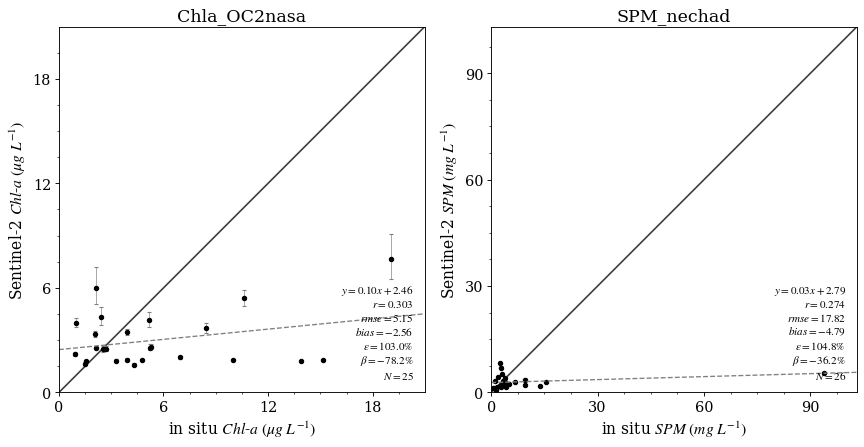

In [16]:
fig, axs = plt.subplots(ncols=len(PARAMS), figsize=(5.5 * len(PARAMS), 5.5))
for ax, (param, (insitu_var, label)) in zip(axs, PARAMS.items()):
    m = matchups[param]
    vmax = 1.1 * max(m.insitu.max(), m.q75.max())
    grstbx.plot_matchup(ax, m.insitu, m['median'], 0, vmax, fmt='.2f',
                 yerr=[m['median'] - m.q25, m.q75 - m['median']], c='k', s=15)
    ax.set_xlabel('in situ ' + label)
    ax.set_ylabel('Sentinel-2 ' + label)
    ax.set_title(param)
fig.tight_layout()

## Notes and references

- The in situ samples are discrete (Niskin bottle) while the satellite value is the median of the
  pixels of the box: part of the scatter comes from the spatial heterogeneity and from the time lag.
- The `eps` and `beta` metrics are less sensitive to outliers than `rmse` and `bias`; they are
  computed in log space and expressed in %.

**References**

- Morley, S. K., Brito, T. V., & Welling, D. T. (2018). Measures of model performance based on the
  log accuracy ratio. *Space Weather*, 16, 69-88.
- Pahlevan, N., et al. (2020). Seamless retrievals of chlorophyll-a from Sentinel-2 (MSI) and
  Sentinel-3 (OLCI) in inland and coastal waters: a machine-learning approach. *Remote Sensing of
  Environment*, 240, 111604.
- Spyrakos, E., et al. (2018). Optical types of inland and coastal waters. *Limnology and
  Oceanography*, 63(2), 846-870.